# 03 · Baseline model: multinomial Logistic Regression

**Goal of this notebook:** train our first model to predict a Serie A result, home win (`H`),
draw (`D`) or away win (`A`), from the pre-match team features of commit 5, and check whether it
beats a naive baseline.

All logic lives in `src/train.py` (splits, pipeline, tuning) and `src/evaluate.py` (metrics,
results table). The same run is available from the command line:

```powershell
python -m src.train
```

| Step | Seasons | Purpose |
|---|---|---|
| Train | 1993-94 to 2024-25 | Fit candidate models |
| Validate | 2025-26 | Choose the feature set and regularisation strength |
| Final training | 1993-94 to 2025-26 | Refit the chosen model on all completed seasons |
| Test | 2026-27, completed matches | Final, untouched evaluation |

The 2026-27 results are never used for training, tuning, imputation or feature selection.
Its *features* can use earlier 2026-27 matches, because each one only looks at results from
dates before the match being predicted (commit 5).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.config import FIGURES_DIR
from src.evaluate import OUTCOME_NAMES, OUTCOMES, metrics_table
from src.feature_engineering import load_features
from src.train import (
    C_GRID, FEATURE_SETS, TEST_SEASON, TRAIN_LAST_SEASON, VALIDATION_SEASON,
    build_model, run_experiment, save_artifacts,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
experiment = run_experiment(features)  # tune -> refit -> test (deterministic)
paths = save_artifacts(experiment)     # same files as `python -m src.train`
for name, path in paths.items():
    print(f"{name:>22}: {path.relative_to(path.parents[2])}")

                 model: outputs\models\logistic_regression.joblib
               metrics: outputs\models\logistic_regression_metrics.json
      test_predictions: outputs\predictions\logistic_regression_test_2026-27.csv
validation_predictions: outputs\predictions\logistic_regression_validation_2025-26.csv


In [2]:
# --- Chart style (same as notebooks 01-02) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, AQUA, ORANGE, GRAY = "#2a78d6", "#1baf7a", "#eb6834", "#a3a29b"
OUTCOME_COLORS = {"H": BLUE, "D": AQUA, "A": ORANGE}
MODEL, BASE = "Logistic Regression", "Baseline (always most frequent)"


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 1. Data and splits

In [3]:
played = features[features["result"].notna()]
split_of = np.select(
    [played["season_start"] <= TRAIN_LAST_SEASON, played["season_start"] == VALIDATION_SEASON,
     played["season_start"] == TEST_SEASON],
    ["1. Train", "2. Validate", "3. Test"], default="unused",
)
split_summary = played.groupby(split_of).agg(
    seasons=("season", lambda s: f"{s.min()} to {s.max()}" if s.nunique() > 1 else s.iloc[0]),
    matches=("result", "size"),
    home_win=("result", lambda r: (r == "H").mean()),
    draw=("result", lambda r: (r == "D").mean()),
    away_win=("result", lambda r: (r == "A").mean()),
)
split_summary.style.format({"matches": "{:,}", "home_win": "{:.1%}", "draw": "{:.1%}", "away_win": "{:.1%}"})

,seasons,matches,home_win,draw,away_win
1. Train,1993-94 to 2024-25,"11,346",45.6%,27.5%,26.9%
2. Validate,2025-26,380,38.9%,26.1%,35.0%
3. Test,2026-27,100,47.0%,16.0%,37.0%


Home wins are the most frequent outcome in training (about 46%), so the **baseline** always
predicts a home win. Its probabilities are the training outcome frequencies, which gives it a
proper log loss as well.

Two things stand out already: home advantage has kept shrinking (only 39% home wins in
2025-26), and the test set is **only 100 matches**, so test scores will be noisy.

## 2. Features and pipeline

Two documented feature sets were compared:

- **`all`**: all 50 pre-match features.
- **`compact`**: 22 features, 11 per team. It keeps one window per feature family (the
  stronger 10-match windows), keeps `ppg` and `gd`, and drops `gf` / `ga` (since
  `gd = gf − ga`) and the 5-match windows, which overlap heavily with the 10-match ones
  (notebook 02).

In [4]:
pd.DataFrame({"compact feature (per team)": [c.removeprefix("home_") for c in FEATURE_SETS["compact"][:11]]})

,compact feature (per team)
0,history_matches
1,form10_ppg
2,form10_gd
3,venue_form10_ppg
4,venue_form10_gd
5,season_played
6,season_ppg
7,season_gd
8,prev_season_ppg
9,prev_season_gd


In [5]:
build_model(C=experiment.C)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.

The pipeline is fitted on training rows only, so nothing from the validation or test season
reaches the imputer or the scaler:

1. **`SimpleImputer(strategy="median", add_indicator=True)`** fills missing history (for
   example last-season stats of promoted teams) with the training median, and **adds a 0/1
   indicator column** for every feature that can be missing. No match is dropped, and the model
   still knows that history was missing. The `promoted` flag is kept as a feature (1 / 0, or
   missing in 1993-94).
2. **`StandardScaler`** puts every feature on the same scale, which L2 regularisation requires
   so it can treat all coefficients fairly.
3. **`LogisticRegression`** is multinomial (one set of coefficients per outcome) with an
   **L2 penalty**. `C` is the inverse penalty strength: smaller `C` means stronger
   regularisation, which keeps the coefficients of the many correlated features small and
   stable.

## 3. Choosing the model on the validation season

Each combination of feature set and `C` is trained on 1993-94 to 2024-25 and scored on 2025-26.
The selection uses **log loss**, because it rewards well-calibrated probabilities rather than
only the single most likely outcome.

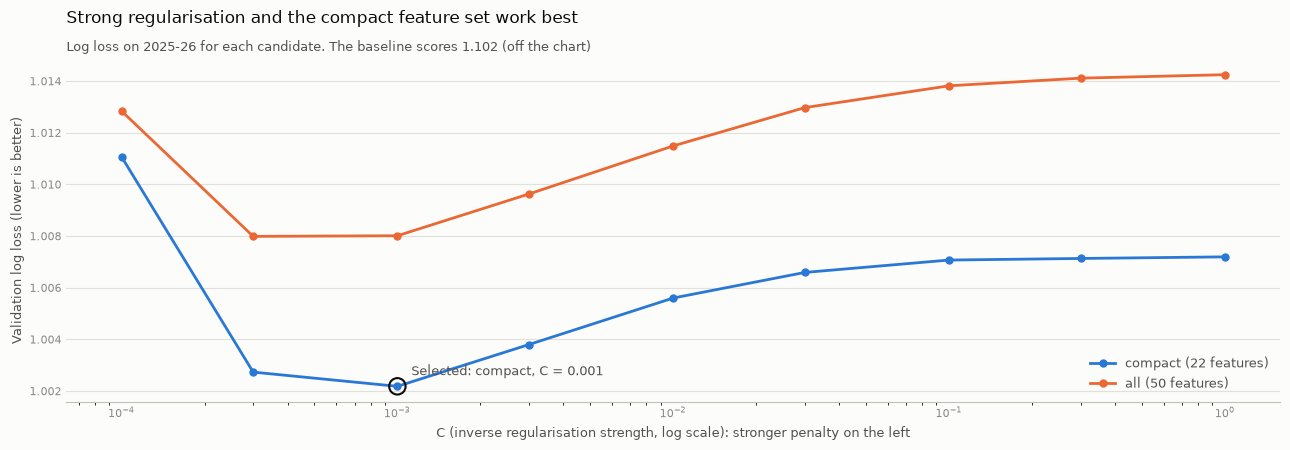

,feature_set,features,C,log_loss,accuracy,macro_f1
0,compact,22,0.001,1.0022,51.8%,0.413
1,compact,22,0.0003,1.0027,52.4%,0.405
2,compact,22,0.003,1.0038,52.1%,0.417
3,compact,22,0.01,1.0056,51.8%,0.415
4,compact,22,0.03,1.0066,52.4%,0.424
5,compact,22,0.1,1.0071,52.6%,0.426


In [6]:
baseline_val_loss = experiment.validation[BASE]["log_loss"]

fig, ax = plt.subplots(figsize=(13, 4.6), facecolor=SURFACE)
for name, color in [("compact", BLUE), ("all", ORANGE)]:
    rows = experiment.tuning[experiment.tuning["feature_set"] == name].sort_values("C")
    ax.plot(rows["C"], rows["log_loss"], color=color, linewidth=2, marker="o", markersize=5,
            label=f"{name} ({rows['features'].iloc[0]} features)")
best = experiment.tuning.iloc[0]
ax.scatter([best["C"]], [best["log_loss"]], s=140, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=5)
ax.annotate(f"Selected: {best['feature_set']}, C = {best['C']:g}", (best["C"], best["log_loss"]),
            xytext=(10, 8), textcoords="offset points", fontsize=9, color=INK_2)
ax.set_xscale("log")
ax.set_xlabel("C (inverse regularisation strength, log scale): stronger penalty on the left",
              color=INK_2, fontsize=9)
ax.set_ylabel("Validation log loss (lower is better)", color=INK_2, fontsize=9)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="lower right")
style_axes(ax)
set_title(ax, "Strong regularisation and the compact feature set work best",
          f"Log loss on 2025-26 for each candidate. The baseline scores {baseline_val_loss:.3f} (off the chart)")
fig.tight_layout()
save_figure(fig, "13_lr_tuning.png")
plt.show()

experiment.tuning.head(6).style.format({"C": "{:g}", "log_loss": "{:.4f}", "accuracy": "{:.1%}", "macro_f1": "{:.3f}"})

**Interpretation**

- Every candidate is far better than the baseline (log loss about 1.00 against 1.10), so the
  choice between candidates matters much less than having the features at all.
- **Strong regularisation helps.** The loss is lowest around `C = 0.001` and rises when the penalty
  is too weak or too strong. This matches notebook 02: many features carry overlapping
  information, and shrinking their coefficients stops the model from over-fitting that overlap.
- The **compact** set is slightly better than all 50 features at every `C`. The differences are
  in the third decimal place, small compared with the noise of a single 380-match season, but
  the simpler model is also easier to explain.

## 4. Results

### Validation season (2025-26, model trained on 1993-94 to 2024-25)

In [7]:
fmt = {"matches": "{:.0f}", "accuracy": "{:.1%}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}",
       "accuracy_H": "{:.1%}", "accuracy_D": "{:.1%}", "accuracy_A": "{:.1%}"}
metrics_table(experiment.validation).style.format(fmt)

,matches,accuracy,macro_f1,log_loss,accuracy_H,accuracy_D,accuracy_A
Logistic Regression,380,51.8%,0.413,1.002,79.1%,3.0%,57.9%
Baseline (always most frequent),380,38.9%,0.187,1.102,100.0%,0.0%,0.0%


### Test season (2026-27, final model trained on 1993-94 to 2025-26)

In [8]:
test_table = metrics_table(experiment.test)
display(test_table.style.format(fmt))

n_test = experiment.test[MODEL]["matches"]
acc = experiment.test[MODEL]["accuracy"]
margin = 1.96 * np.sqrt(acc * (1 - acc) / n_test)
print(f"Test accuracy {acc:.1%}, approximate 95% interval {acc - margin:.1%} to {acc + margin:.1%} "
      f"({n_test} matches)")

,matches,accuracy,macro_f1,log_loss,accuracy_H,accuracy_D,accuracy_A
Logistic Regression,100,60.0%,0.460,0.882,80.9%,6.2%,56.8%
Baseline (always most frequent),100,47.0%,0.213,1.060,100.0%,0.0%,0.0%


Test accuracy 60.0%, approximate 95% interval 50.4% to 69.6% (100 matches)


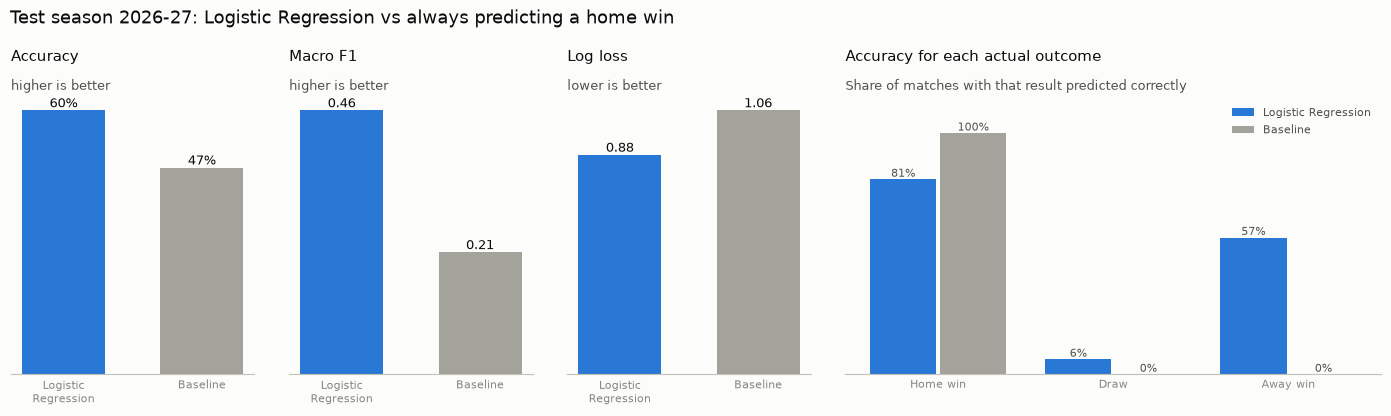

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), facecolor=SURFACE,
                         gridspec_kw={"width_ratios": [1, 1, 1, 2.2]})
panels = [("accuracy", "Accuracy", "higher is better", "{:.0%}"),
          ("macro_f1", "Macro F1", "higher is better", "{:.2f}"),
          ("log_loss", "Log loss", "lower is better", "{:.2f}")]
names, colors = [MODEL, BASE], [BLUE, GRAY]
for ax, (key, title, note, label_fmt) in zip(axes, panels):
    values = [experiment.test[n][key] for n in names]
    ax.bar([0, 1], values, color=colors, width=0.6)
    for x, v in zip([0, 1], values):
        ax.text(x, v, label_fmt.format(v), ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks([0, 1], ["Logistic\nRegression", "Baseline"], fontsize=8)
    ax.set_yticks([])
    style_axes(ax, grid=None)
    set_title(ax, title, note, size=11)

# Per-class accuracy: model vs baseline
ax = axes[3]
x = np.arange(len(OUTCOMES))
for offset, name, color in [(-0.2, MODEL, BLUE), (0.2, BASE, GRAY)]:
    values = [experiment.test[name]["per_class_accuracy"][o] for o in OUTCOMES]
    ax.bar(x + offset, values, width=0.38, color=color, label="Logistic Regression" if name == MODEL else "Baseline")
    for xi, v in zip(x + offset, values):
        ax.text(xi, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(x, [OUTCOME_NAMES[o] for o in OUTCOMES], fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_yticks([])
ax.legend(frameon=False, fontsize=8, labelcolor=INK_2, loc="upper right")
style_axes(ax, grid=None)
set_title(ax, "Accuracy for each actual outcome", "Share of matches with that result predicted correctly", size=11)

fig.suptitle("Test season 2026-27: Logistic Regression vs always predicting a home win",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=2.5)
save_figure(fig, "14_lr_test_metrics.png")
plt.show()

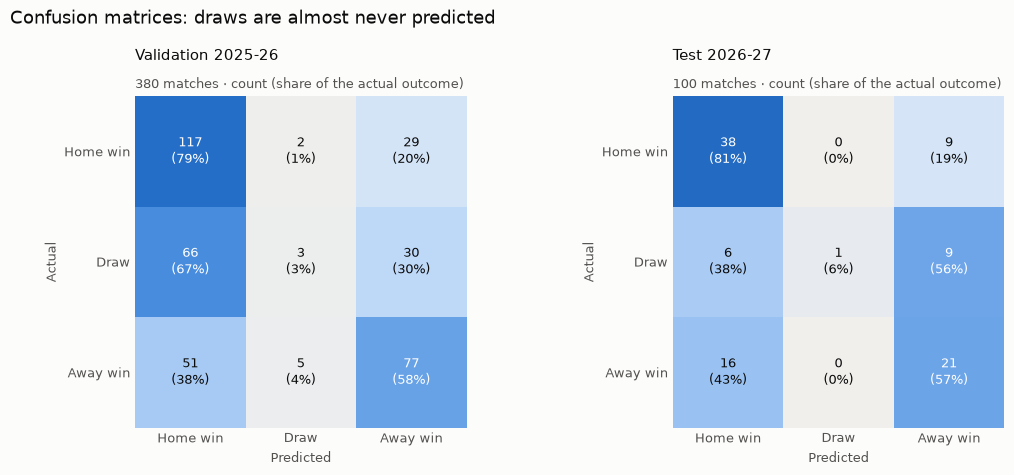

In [10]:
seq_cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), facecolor=SURFACE)
for ax, (label, results) in zip(axes, [("Validation 2025-26", experiment.validation),
                                        ("Test 2026-27", experiment.test)]):
    matrix = results[MODEL]["confusion_matrix"]
    shares = matrix.div(matrix.sum(axis=1), axis=0)  # share of each actual outcome
    ax.imshow(shares.values, cmap=seq_cmap, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matrix.iloc[i, j]}\n({shares.iloc[i, j]:.0%})", ha="center", va="center",
                    fontsize=9, color="#ffffff" if shares.iloc[i, j] > 0.55 else INK)
    ax.set_xticks(range(3), [OUTCOME_NAMES[o] for o in OUTCOMES], fontsize=9, color=INK_2)
    ax.set_yticks(range(3), [OUTCOME_NAMES[o] for o in OUTCOMES], fontsize=9, color=INK_2)
    ax.set_xlabel("Predicted", color=INK_2, fontsize=9)
    ax.set_ylabel("Actual", color=INK_2, fontsize=9)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    set_title(ax, label, f"{results[MODEL]['matches']} matches · count (share of the actual outcome)", size=11)
fig.suptitle("Confusion matrices: draws are almost never predicted", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "15_lr_confusion_matrices.png")
plt.show()

**Interpretation**

- On both evaluation seasons the model clearly **beats the baseline on every overall metric**:
  - **Validation:** accuracy 51.8% against 38.9%, log loss 1.002 against 1.102.
  - **Test:** accuracy 60.0% against 47.0%, log loss 0.882 against 1.060.

  The macro F1 roughly doubles, because the model also predicts away wins well, which the
  baseline never does.
- The test season looks unusually good, but with only 100 matches its accuracy has a 95% interval
  of roughly ±10 points. The **validation season (380 matches) is the more reliable estimate**,
  at about 52%.
- **Draws are the weak spot.** The model predicts a draw only a handful of times, so almost every
  draw is misclassified. The next section shows why.

## 5. Why draws are never predicted

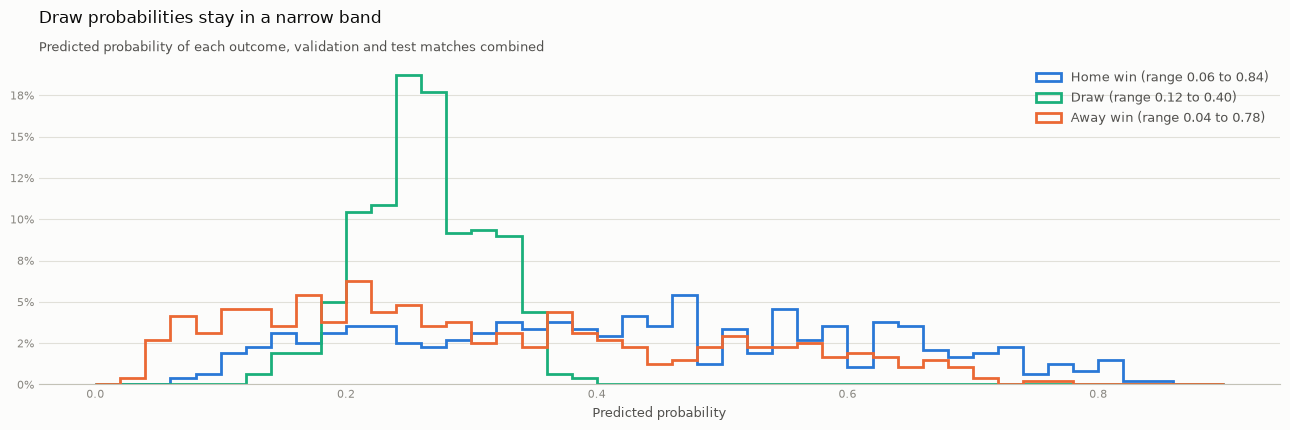

,actual share,predicted share,mean predicted probability
Home win,40.6%,61.3%,42.8%
Draw,24.0%,2.3%,26.2%
Away win,35.4%,36.5%,31.0%


In [11]:
probs = pd.concat([experiment.validation_results.assign(split="Validation 2025-26"),
                   experiment.test_results.assign(split="Test 2026-27")], ignore_index=True)
prob_cols = {"H": "prob_home_win", "D": "prob_draw", "A": "prob_away_win"}

fig, ax = plt.subplots(figsize=(13, 4.4), facecolor=SURFACE)
bins = np.linspace(0, 0.9, 46)
for outcome in OUTCOMES:
    values = probs[prob_cols[outcome]]
    ax.hist(values, bins=bins, histtype="step", linewidth=2, color=OUTCOME_COLORS[outcome],
            label=f"{OUTCOME_NAMES[outcome]} (range {values.min():.2f} to {values.max():.2f})",
            weights=np.full(len(values), 1 / len(values)))
ax.set_xlabel("Predicted probability", color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper right")
style_axes(ax)
set_title(ax, "Draw probabilities stay in a narrow band",
          "Predicted probability of each outcome, validation and test matches combined")
fig.tight_layout()
save_figure(fig, "16_lr_probability_distributions.png")
plt.show()

shares = pd.DataFrame({
    "actual share": probs["actual"].value_counts(normalize=True),
    "predicted share": probs["predicted"].value_counts(normalize=True),
    "mean predicted probability": pd.Series({o: probs[prob_cols[o]].mean() for o in OUTCOMES}),
}).reindex(OUTCOMES).rename(index=OUTCOME_NAMES).fillna(0)
shares.style.format("{:.1%}")

**Interpretation**

- The model's **average** draw probability (about 26%) is close to how often draws really
  happened in these two seasons (24%), so its probabilities are sensible on average.
- Draw probabilities vary much less than home and away probabilities: they stay between about
  0.12 and 0.40. A draw is only the most likely outcome when both teams are very evenly
  matched, and even then a home or away win is usually rated slightly higher.
- This isn't a bug. It's a well-known property of football prediction: draws are common but
  hard to pin down. Picking the highest probability throws away information, so the
  **probabilities themselves** are the more useful output (for example, a 35% draw
  probability is still meaningful).

## 6. What the model learned

The final model's coefficients are comparable because all inputs are standardised. Below is
the difference between the home-win and away-win coefficient for each input: positive values push
towards a **home win**, negative values towards an **away win**.

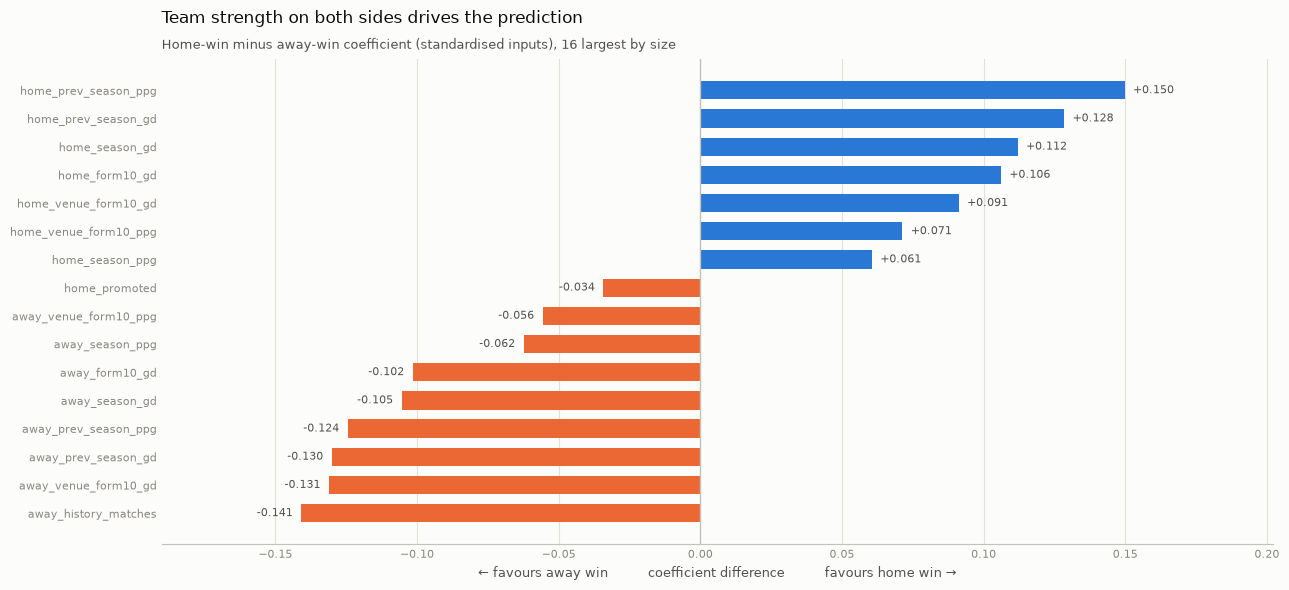

In [12]:
pipeline = experiment.model
input_names = pipeline.named_steps["impute"].get_feature_names_out(experiment.feature_columns)
lr = pipeline.named_steps["model"]
coef = pd.DataFrame(lr.coef_.T, index=input_names, columns=lr.classes_)
coef["home_vs_away"] = coef["H"] - coef["A"]
top = coef["home_vs_away"].reindex(coef["home_vs_away"].abs().sort_values(ascending=False).index).head(16)
top = top.sort_values()

fig, ax = plt.subplots(figsize=(13, 6), facecolor=SURFACE)
y = np.arange(len(top))
ax.barh(y, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.65)
for yi, v in zip(y, top.values):
    ax.text(v + (0.003 if v > 0 else -0.003), yi, f"{v:+.3f}", va="center",
            ha="left" if v > 0 else "right", fontsize=8, color=INK_2)
ax.set_yticks(y, [n.replace("missingindicator_", "missing: ") for n in top.index], fontsize=9, color=INK_2)
ax.axvline(0, color=BASELINE, linewidth=1)
ax.set_xlim(top.min() * 1.35, top.max() * 1.35)
ax.set_xlabel("← favours away win          coefficient difference          favours home win →",
              color=INK_2, fontsize=9)
style_axes(ax, grid="x")
set_title(ax, "Team strength on both sides drives the prediction",
          "Home-win minus away-win coefficient (standardised inputs), 16 largest by size")
fig.tight_layout()
save_figure(fig, "17_lr_coefficients.png")
plt.show()

**Interpretation**

- The model is **symmetric and intuitive**. A strong home team (last season's points and goal
  difference, this season's goal difference, 10-match form) pushes towards a home win, and the
  same features for the away team push towards an away win.
- **Last-season** and **season-to-date** strength carry the most weight, followed by 10-match
  form, which matches the ranking of feature signal in notebook 02.
- `history_matches` matters too: long-established Serie A clubs are generally stronger.
- The **missing-value indicators** get small but sensible weights. For example, a home team with
  missing history, which is usually a promoted side, nudges the prediction towards an away win.
- With strong regularisation, all coefficients are small, so these are **directions and
  relative sizes**, not precise effects. Correlated features also share credit with each other.

## 7. Match-by-match predictions (test season)

The full table is saved to `outputs/predictions/logistic_regression_test_2026-27.csv`.

In [13]:
test_results = experiment.test_results
print(f"{len(test_results)} matches, {test_results['correct'].sum()} predicted correctly")
test_results.head(15).style.format(
    {"date": "{:%Y-%m-%d}", "prob_home_win": "{:.1%}", "prob_draw": "{:.1%}", "prob_away_win": "{:.1%}"}
)

100 matches, 60 predicted correctly


,date,home_team,away_team,actual,predicted,prob_home_win,prob_draw,prob_away_win,correct
0,2026-08-22,Inter,Monza,H,H,75.6%,18.3%,6.1%,True
1,2026-08-22,Udinese,Como,D,A,27.2%,30.5%,42.3%,False
2,2026-08-22,Genoa,Napoli,A,A,23.5%,27.9%,48.6%,True
3,2026-08-22,Parma,Cagliari,A,H,40.9%,33.7%,25.3%,False
4,2026-08-23,Frosinone,Juventus,A,A,21.0%,23.0%,56.0%,True
5,2026-08-23,Venezia,Lecce,A,H,42.4%,29.4%,28.2%,False
6,2026-08-23,Atalanta,Sassuolo,H,H,54.1%,28.3%,17.6%,True
7,2026-08-23,Torino,Milan,A,A,27.7%,26.6%,45.7%,True
8,2026-08-24,Bologna,Lazio,A,A,31.6%,27.5%,40.9%,True
9,2026-08-24,Roma,Fiorentina,H,H,59.4%,23.6%,17.0%,True


In [14]:
# Most confident predictions, right and wrong
test_results["confidence"] = test_results[["prob_home_win", "prob_draw", "prob_away_win"]].max(axis=1)
cols = ["date", "home_team", "away_team", "actual", "predicted", "prob_home_win", "prob_draw", "prob_away_win"]
fmt_probs = {"date": "{:%Y-%m-%d}", "prob_home_win": "{:.1%}", "prob_draw": "{:.1%}", "prob_away_win": "{:.1%}"}
print("Most confident correct predictions:")
display(test_results[test_results["correct"]].nlargest(5, "confidence")[cols].style.format(fmt_probs))
print("Most confident wrong predictions (upsets):")
display(test_results[~test_results["correct"]].nlargest(5, "confidence")[cols].style.format(fmt_probs))

Most confident correct predictions:


,date,home_team,away_team,actual,predicted,prob_home_win,prob_draw,prob_away_win
75,2026-10-25,Inter,Fiorentina,H,H,81.4%,13.2%,5.3%
51,2026-10-10,Inter,Parma,H,H,81.3%,14.4%,4.3%
63,2026-10-17,Roma,Genoa,H,H,80.1%,15.2%,4.7%
85,2026-10-28,Venezia,Inter,A,A,7.6%,14.8%,77.5%
93,2026-11-01,Como,Venezia,H,H,76.1%,18.3%,5.6%


Most confident wrong predictions (upsets):


,date,home_team,away_team,actual,predicted,prob_home_win,prob_draw,prob_away_win
99,2026-11-02,Atalanta,Parma,A,H,63.3%,24.6%,12.1%
61,2026-10-17,Venezia,Napoli,H,A,15.0%,21.8%,63.2%
83,2026-10-28,Milan,Bologna,A,H,57.1%,25.3%,17.5%
33,2026-09-12,Atalanta,Cagliari,A,H,55.4%,28.6%,16.0%
76,2026-10-25,Atalanta,Frosinone,D,H,55.2%,29.9%,14.9%


## Key findings

| Finding | Detail |
|---|---|
| The model beats the baseline | Validation: 51.8% vs 38.9% accuracy, log loss 1.002 vs 1.102. Test: 60.0% vs 47.0%, log loss 0.882 vs 1.060 |
| Best setup | Compact 22-feature set, strong L2 regularisation (`C = 0.001`) |
| Draws are never really predicted | Draw probabilities stay at about 0.12–0.40, so draws are rarely the most likely outcome |
| Team strength drives predictions | Last-season and season-to-date goal difference and points matter most |
| The test set is small | 100 matches, so about ±10 points of uncertainty on accuracy; the 380-match validation season is the steadier estimate |

## Next steps

- **Commit 7:** Random Forest and XGBoost, evaluated on the same chronological splits and
  metrics, to see whether non-linear models beat this Logistic Regression baseline.